# Credit Score Classification with Human-in-the-Loop (Random Forest, improved)

This notebook rebuilds the Random Forest HITL pipeline with five fixes over the original version:

1. **Customer-level split.** Each customer has 8 monthly rows. A random row split puts the same customer in train and test, which inflates accuracy. Here the data is split by `Customer_ID`.
2. **Calibrated confidence.** Routing depends on `predict_proba`, so the probabilities are calibrated (isotonic, grouped CV) before they are used as confidence.
3. **Threshold chosen on validation data.** τ is chosen on a validation set and then evaluated once on the untouched test set.
4. **More realistic reviewer.** The simulated human is less accurate on hard cases, and we test how results change as human accuracy drops.
5. **Every chart comes from computed results.** No numbers are typed in by hand.

It also adds a **cost-aware routing policy**, where mistakes have different costs (calling a *Poor* customer *Good* is worse than the reverse) and each review has a cost.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

DATA_PATH = "../data/credit_score_train.csv"  # see data/README.md
RANDOM_STATE = 42

# Human reviewer simulation
HUMAN_ACC_EASY = 0.95   # reviewer accuracy on cases the model is fairly sure about
HUMAN_ACC_HARD = 0.85   # reviewer accuracy on the hardest cases
MAX_REVIEW_RATE = 0.30  # review capacity: at most 30% of cases can go to a human

sns.set_theme(style="whitegrid")

## 2. Load data and quick EDA

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Customers:", df["Customer_ID"].nunique(),
      "| rows per customer:", df.groupby("Customer_ID").size().value_counts().to_dict())
df.head()

Shape: (100000, 28)
Customers: 12500 | rows per customer: {8: 12500}


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


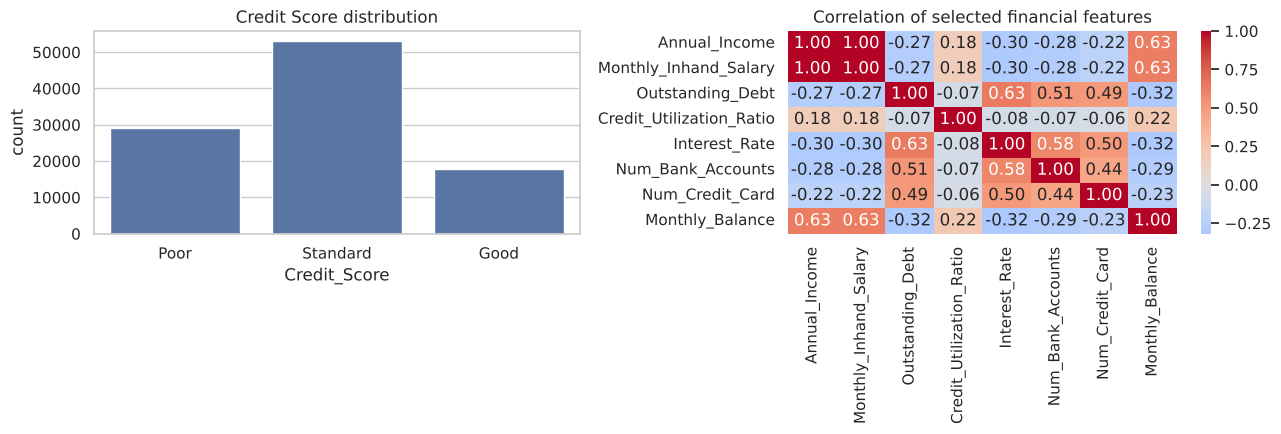

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="Credit_Score", order=["Poor", "Standard", "Good"], ax=axes[0])
axes[0].set_title("Credit Score distribution")

cols = ["Annual_Income", "Monthly_Inhand_Salary", "Outstanding_Debt", "Credit_Utilization_Ratio",
        "Interest_Rate", "Num_Bank_Accounts", "Num_Credit_Card", "Monthly_Balance"]
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlation of selected financial features")
plt.tight_layout(); plt.show()

## 3. Features
Same feature set as the original notebook: drop identifiers and high-cardinality text, and replace debt and income with `debt_to_income`.

In [4]:
groups = df["Customer_ID"].to_numpy()
y = df["Credit_Score"].astype(str).to_numpy(dtype=object)

X = df.drop(columns=["ID", "Customer_ID", "Name", "SSN", "Credit_Score",
                     "Type_of_Loan", "Payment_Behaviour"]).copy()
X["debt_to_income"] = X["Outstanding_Debt"] / X["Annual_Income"].replace(0, np.nan)
X = X.drop(columns=["Outstanding_Debt", "Annual_Income"])

categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numerical = [c for c in X.columns if c not in categorical]
print("Categorical:", categorical)
print("Numerical:", len(numerical), "columns")
print("Missing values:", int(X.isna().sum().sum()))

Categorical: ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount']
Numerical: 17 columns
Missing values: 0


## 4. Customer-level split: train / validation / test
- **Test (20% of customers):** used once, at the very end.
- **Validation (20% of the remaining customers):** used to choose τ and the routing policy.
- **Train:** everything else.

No customer appears in more than one set.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
trval_idx, test_idx = next(gss.split(X, y, groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
tr_rel, val_rel = next(gss2.split(X.iloc[trval_idx], y[trval_idx], groups[trval_idx]))
train_idx, val_idx = trval_idx[tr_rel], trval_idx[val_rel]

X_train, y_train, g_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
X_val, y_val = X.iloc[val_idx], y[val_idx]
X_test, y_test = X.iloc[test_idx], y[test_idx]

assert not (set(g_train) & set(groups[val_idx])) and not (set(g_train) & set(groups[test_idx]))
print(f"train {len(train_idx):,} | val {len(val_idx):,} | test {len(test_idx):,} rows")

train 64,000 | val 16,000 | test 20,000 rows


## 5. Models
The preprocessing sits inside a `Pipeline`, so it is fit on training data only.

In [6]:
def make_preprocessor():
    return ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", StandardScaler(), numerical),
    ])

rf_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                  random_state=RANDOM_STATE)),
])

# Calibration folds are grouped by customer too, otherwise calibration is fit on leaked rows
cal_folds = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
rf_cal = CalibratedClassifierCV(rf_pipe, method="isotonic", cv=cal_folds)

hgb_pipe = Pipeline([
    ("prep", ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)],
                               remainder="passthrough")),
    ("hgb", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=RANDOM_STATE)),
])

models = {"Random Forest": rf_pipe, "Random Forest (calibrated)": rf_cal, "HistGradientBoosting": hgb_pipe}
for name, m in models.items():
    m.fit(X_train, y_train)
    print("fitted:", name)

fitted: Random Forest


fitted: Random Forest (calibrated)


fitted: HistGradientBoosting


In [7]:
def evaluate(m, X_, y_):
    p = m.predict_proba(X_)
    pred = m.classes_[p.argmax(1)]
    onehot = (y_[:, None] == m.classes_[None, :]).astype(float)
    return {"accuracy": accuracy_score(y_, pred),
            "macro_F1": f1_score(y_, pred, average="macro"),
            "log_loss": log_loss(y_, p, labels=m.classes_),
            "brier": ((p - onehot) ** 2).sum(1).mean()}

results = pd.DataFrame({name: evaluate(m, X_val, y_val) for name, m in models.items()}).T
results.round(4)

,accuracy,macro_F1,log_loss,brier
Random Forest,0.7041,0.6807,0.6492,0.3917
Random Forest (calibrated),0.7068,0.6875,0.6396,0.3872
HistGradientBoosting,0.7034,0.6767,0.6657,0.4016


### How much did the old random row split inflate accuracy?
The same Random Forest, trained on a random row split. The gap between this number and the grouped result above is the leakage.

In [8]:
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
leaky = Pipeline([("prep", make_preprocessor()),
                  ("rf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))]).fit(Xa, ya)
leaky_acc = accuracy_score(yb, leaky.predict(Xb))
print(f"Random row split (original method): {leaky_acc:.4f}")
print(f"Customer-level split (validation):  {results.loc['Random Forest', 'accuracy']:.4f}")

Random row split (original method): 0.8308
Customer-level split (validation):  0.7041


### Calibration check
For a well-calibrated model, cases predicted with 80% confidence are correct about 80% of the time. HITL routing relies on this.

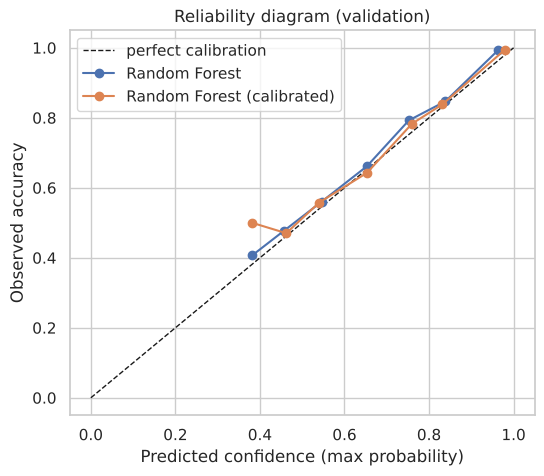

In [9]:
def reliability(m, X_, y_, bins=10):
    p = m.predict_proba(X_)
    conf = p.max(1); correct = (m.classes_[p.argmax(1)] == y_)
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    rows = [(conf[idx == b].mean(), correct[idx == b].mean(), (idx == b).sum()) for b in range(bins) if (idx == b).any()]
    return pd.DataFrame(rows, columns=["confidence", "accuracy", "n"])

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
for name in ["Random Forest", "Random Forest (calibrated)"]:
    r = reliability(models[name], X_val, y_val)
    plt.plot(r.confidence, r.accuracy, marker="o", label=name)
plt.xlabel("Predicted confidence (max probability)"); plt.ylabel("Observed accuracy")
plt.title("Reliability diagram (validation)"); plt.legend(); plt.show()

In [10]:
model = models["Random Forest (calibrated)"]   # the model used for HITL from here on
classes = model.classes_
P_val, P_test = model.predict_proba(X_val), model.predict_proba(X_test)
print("Classes:", list(classes))

Classes: ['Good', 'Poor', 'Standard']


## 6. Simulated human reviewer
The original notebook assumed a flat 95% human accuracy. Real reviewers also find the ambiguous cases harder. Here human accuracy falls linearly from `HUMAN_ACC_EASY` to `HUMAN_ACC_HARD` as model confidence drops. When the reviewer is wrong, they pick one of the other classes at random.

In [11]:
def human_review(y_true, conf, acc_easy=HUMAN_ACC_EASY, acc_hard=HUMAN_ACC_HARD, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    k = len(classes)
    difficulty = np.clip((1 - conf) / (1 - 1 / k), 0, 1)        # 0 = easy, 1 = hardest
    p_correct = acc_easy - (acc_easy - acc_hard) * difficulty
    correct = rng.random(len(y_true)) < p_correct
    wrong = np.array([rng.choice([c for c in classes if c != t]) for t in y_true])
    return np.where(correct, y_true, wrong)

## 7. Confidence-threshold routing: sweep τ on validation
A case goes to a human when the model's confidence is below τ.

In [12]:
def route_threshold(P, y_true, tau, **hkw):
    conf = P.max(1); ai_pred = classes[P.argmax(1)]
    review = conf < tau
    final = ai_pred.copy()
    if review.any():
        final[review] = human_review(y_true[review], conf[review], **hkw)
    return final, review

taus = np.round(np.arange(0.40, 0.96, 0.01), 2)   # fine grid so the capacity limit can be hit closely
rows = []
for t in taus:
    final, review = route_threshold(P_val, y_val, t)
    auto = ~review
    rows.append({"tau": t, "review_rate": review.mean(),
                 "final_accuracy": accuracy_score(y_val, final),
                 "auto_accuracy": accuracy_score(y_val[auto], classes[P_val[auto].argmax(1)]) if auto.any() else np.nan})
sweep = pd.DataFrame(rows)
sweep[np.isclose((sweep.tau * 100) % 5, 0)].round(3)   # show every 0.05; all rows are kept in `sweep`

,tau,review_rate,final_accuracy,auto_accuracy
0,0.40,0.007,0.710,0.708
5,0.45,0.060,0.732,0.723
10,0.50,0.171,0.774,0.755
15,0.55,0.309,0.822,0.798
20,0.60,0.383,0.845,0.823
25,0.65,0.418,0.855,0.837
30,0.70,0.463,0.866,0.850
35,0.75,0.540,0.877,0.868
40,0.80,0.682,0.894,0.896
45,0.85,0.840,0.910,0.966


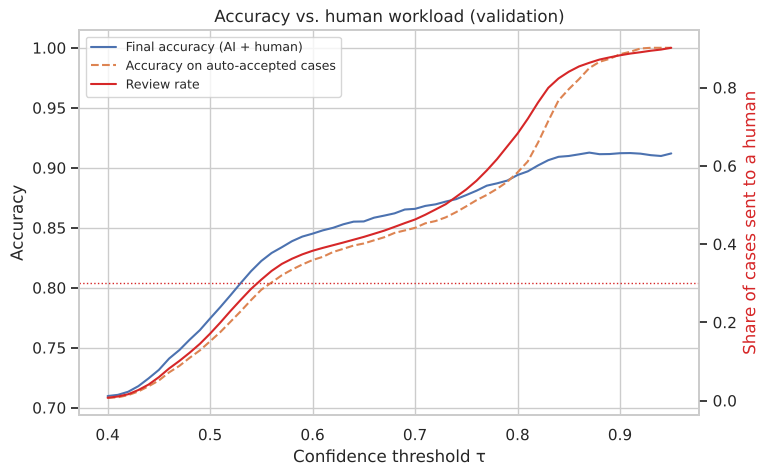

In [13]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(sweep.tau, sweep.final_accuracy, label="Final accuracy (AI + human)")
ax1.plot(sweep.tau, sweep.auto_accuracy, ls="--", label="Accuracy on auto-accepted cases")
ax1.set_xlabel("Confidence threshold τ"); ax1.set_ylabel("Accuracy")
ax2 = ax1.twinx()
ax2.plot(sweep.tau, sweep.review_rate, color="tab:red", label="Review rate")
ax2.axhline(MAX_REVIEW_RATE, color="tab:red", ls=":", lw=1)
ax2.set_ylabel("Share of cases sent to a human", color="tab:red"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
plt.title("Accuracy vs. human workload (validation)"); plt.show()

### Choose τ under a review-capacity limit
The highest-accuracy τ whose review rate stays within `MAX_REVIEW_RATE`.

In [14]:
feasible = sweep[sweep.review_rate <= MAX_REVIEW_RATE]
tau_star = feasible.loc[feasible.final_accuracy.idxmax(), "tau"]
print(f"Chosen τ = {tau_star}  (validation review rate ≤ {MAX_REVIEW_RATE:.0%})")
feasible.loc[feasible.tau == tau_star].round(3)

Chosen τ = 0.54  (validation review rate ≤ 30%)


,tau,review_rate,final_accuracy,auto_accuracy
14,0.54,0.286,0.814,0.79


## 8. Cost-aware routing
Confidence alone treats every mistake the same. In credit scoring, approving a *Poor* customer as *Good* costs far more than under-rating a *Good* one. Below, `COST[true][pred]` is the cost of an AI decision and `REVIEW_COST` is the cost of one human review. **These numbers are placeholders: replace them with your business's real costs.**

For each case, the policy takes the AI decision with the lowest expected cost, using the calibrated probabilities. It sends the case to a human when that expected cost is higher than the cost of a review plus the expected cost of a human mistake.

In [15]:
COST = pd.DataFrame(  # rows = true class, columns = predicted class
    {"Good":     [0, 2, 10],   # predicting Good for a Poor customer is the costliest error
     "Standard": [1, 0, 3],
     "Poor":     [3, 2, 0]},
    index=["Good", "Standard", "Poor"]).loc[list(classes), list(classes)]
REVIEW_COST = 0.6
C = COST.values
display(COST)

def route_cost(P, y_true, review_cost=REVIEW_COST, **hkw):
    exp_cost = P @ C                         # expected cost of predicting each class
    best = exp_cost.argmin(1)
    ai_cost = exp_cost[np.arange(len(P)), best]
    conf = P.max(1)
    human_err = 1 - (HUMAN_ACC_EASY - (HUMAN_ACC_EASY - HUMAN_ACC_HARD) * np.clip((1 - conf) / (1 - 1/len(classes)), 0, 1))
    human_cost = review_cost + human_err * C[C > 0].mean()
    review = ai_cost > human_cost
    final = classes[best].copy()
    if review.any():
        final[review] = human_review(y_true[review], conf[review], **hkw)
    return final, review

def total_cost(y_true, final, review, review_cost=REVIEW_COST):
    ti = pd.Index(classes).get_indexer(y_true); pi = pd.Index(classes).get_indexer(final)
    return (C[ti, pi].sum() + review.sum() * review_cost) / len(y_true)

,Good,Poor,Standard
Good,0,3,1
Poor,10,0,3
Standard,2,2,0


In [16]:
policies = {}
f, r = classes[P_val.argmax(1)], np.zeros(len(y_val), bool);           policies["AI only"] = (f, r)
policies[f"Threshold τ={tau_star}"] = route_threshold(P_val, y_val, tau_star)
policies["Cost-aware"] = route_cost(P_val, y_val)

summary_val = pd.DataFrame({k: {"accuracy": accuracy_score(y_val, f), "review_rate": r.mean(),
                                "cost_per_case": total_cost(y_val, f, r)}
                            for k, (f, r) in policies.items()}).T
summary_val.round(3)

,accuracy,review_rate,cost_per_case
AI only,0.707,0.000,0.785
Threshold τ=0.54,0.814,0.286,0.642
Cost-aware,0.735,0.153,0.581


## 9. Final evaluation on the untouched test set
τ and the costs were all set on validation data. This is the only time the test set is used.

In [17]:
test_policies = {
    "AI only": (classes[P_test.argmax(1)], np.zeros(len(y_test), bool)),
    f"Threshold τ={tau_star}": route_threshold(P_test, y_test, tau_star),
    "Cost-aware": route_cost(P_test, y_test),
}
summary_test = pd.DataFrame({k: {"accuracy": accuracy_score(y_test, f),
                                 "macro_F1": f1_score(y_test, f, average="macro"),
                                 "review_rate": r.mean(),
                                 "cost_per_case": total_cost(y_test, f, r)}
                             for k, (f, r) in test_policies.items()}).T
summary_test.round(3)

,accuracy,macro_F1,review_rate,cost_per_case
AI only,0.708,0.687,0.000,0.782
Threshold τ=0.54,0.808,0.797,0.274,0.637
Cost-aware,0.724,0.635,0.156,0.600


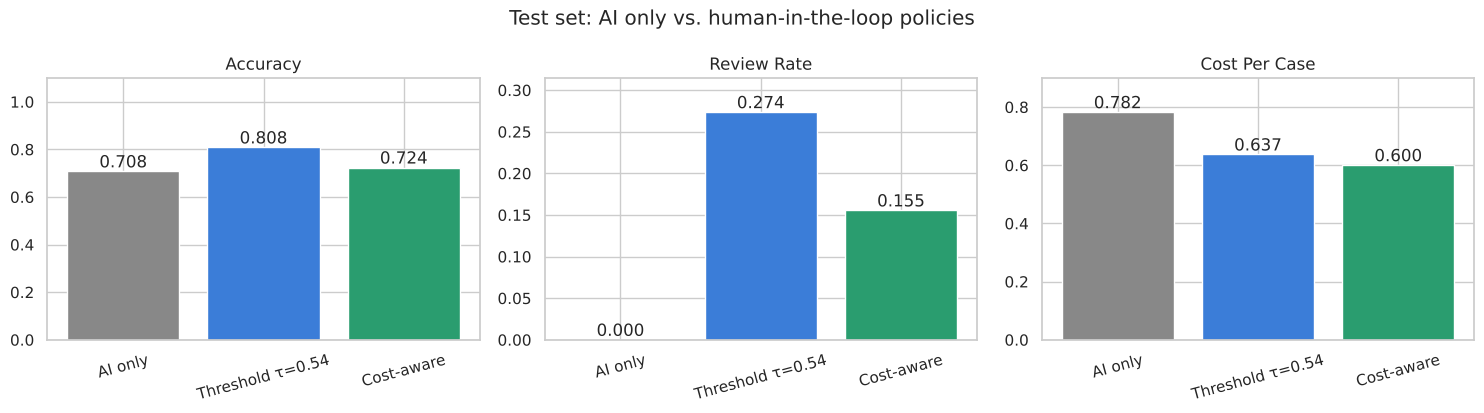

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ["accuracy", "review_rate", "cost_per_case"]):
    bars = ax.bar(summary_test.index, summary_test[col], color=["#888", "#3b7dd8", "#2a9d6f"])
    ax.bar_label(bars, fmt="%.3f"); ax.margins(y=0.15); ax.set_title(col.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylim(0, 1.1)
plt.suptitle("Test set: AI only vs. human-in-the-loop policies"); plt.tight_layout(); plt.show()

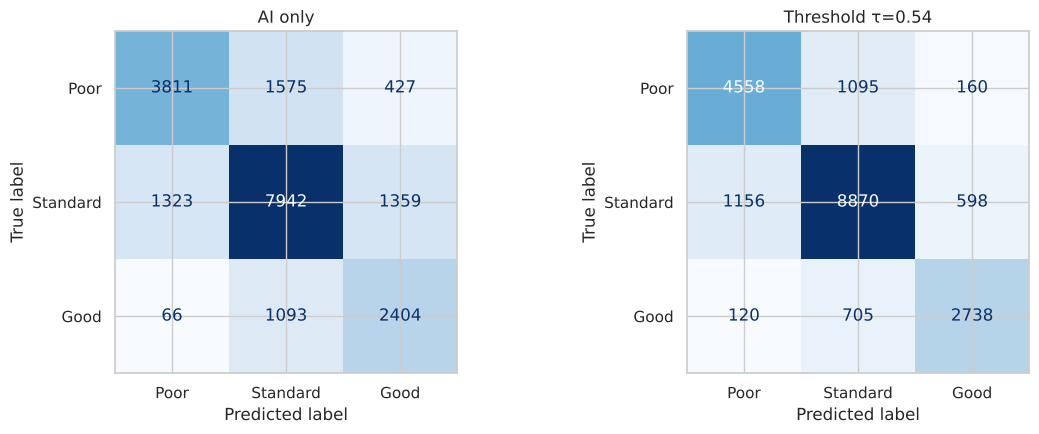

              precision    recall  f1-score   support

        Good      0.783     0.768     0.776      3563
        Poor      0.781     0.784     0.783      5813
    Standard      0.831     0.835     0.833     10624

    accuracy                          0.808     20000
   macro avg      0.799     0.796     0.797     20000
weighted avg      0.808     0.808     0.808     20000



In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order = [c for c in ["Poor", "Standard", "Good"] if c in classes]
for ax, name in zip(axes, ["AI only", f"Threshold τ={tau_star}"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, test_policies[name][0], labels=order),
                           display_labels=order).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()
print(classification_report(y_test, test_policies[f"Threshold τ={tau_star}"][0], digits=3))

## 10. Sensitivity: what if reviewers are less accurate?
The HITL gain depends on how good the humans are. This repeats the test evaluation with weaker reviewers. Hard-case accuracy is kept 10 points below easy-case accuracy.

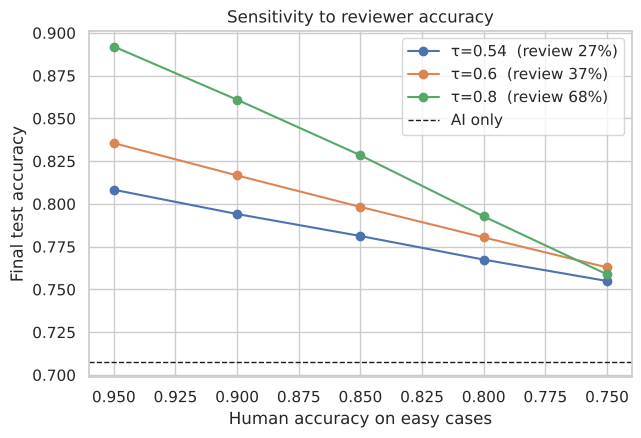

tau,0.54,0.60,0.80
human_acc_easy,,,
0.75,0.755,0.763,0.759
0.80,0.767,0.780,0.793
0.85,0.781,0.798,0.828
0.90,0.794,0.817,0.861
0.95,0.808,0.836,0.892


In [20]:
rows = []
for acc in [0.95, 0.90, 0.85, 0.80, 0.75]:
    for t in sorted({0.6, float(tau_star), 0.8}):
        f, r = route_threshold(P_test, y_test, t, acc_easy=acc, acc_hard=acc - 0.10)
        rows.append({"human_acc_easy": acc, "tau": t, "accuracy": accuracy_score(y_test, f), "review_rate": r.mean()})
sens = pd.DataFrame(rows)
ai_only = summary_test.loc["AI only", "accuracy"]

plt.figure(figsize=(7, 4.5))
for t, g in sens.groupby("tau"):
    plt.plot(g.human_acc_easy, g.accuracy, marker="o", label=f"τ={t}  (review {g.review_rate.iloc[0]:.0%})")
plt.axhline(ai_only, color="k", ls="--", lw=1, label="AI only")
plt.gca().invert_xaxis()
plt.xlabel("Human accuracy on easy cases"); plt.ylabel("Final test accuracy")
plt.title("Sensitivity to reviewer accuracy"); plt.legend(); plt.show()
sens.pivot(index="human_acc_easy", columns="tau", values="accuracy").round(3)

## 11. What drives the model? Feature importance

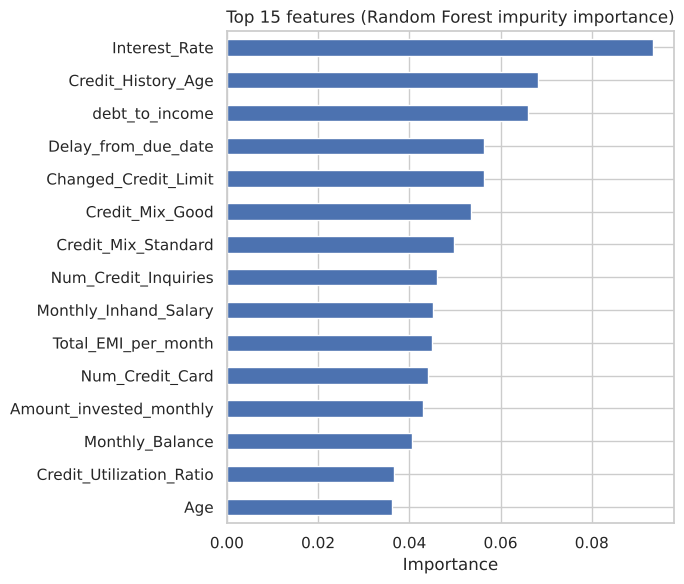

In [21]:
rf_fitted = models["Random Forest"].named_steps["rf"]
names = models["Random Forest"].named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_fitted.feature_importances_, index=[n.split("__", 1)[1] for n in names]).sort_values()
imp.tail(15).plot.barh(figsize=(7, 6), title="Top 15 features (Random Forest impurity importance)")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

## 12. Summary and next steps
- **Expect lower AI-only accuracy than the original 83%.** The customer-level split removes leakage, so this figure is closer to performance on new customers.
- **Calibrated probabilities** make τ mean what it says. A case at 0.8 confidence is right about 80% of the time.
- **τ was chosen on validation data under a review-capacity limit**, so the test accuracy is an honest estimate.
- **Cost-aware routing** sends a case to a human when a mistake would be expensive, not only when the model is unsure. Replace the placeholder `COST` and `REVIEW_COST` with real figures.
- **Sensitivity analysis** shows how much of the gain depends on reviewer quality.

Possible next steps: tune RF and HGB with `GroupKFold` search; add customer-history features (lags or trends over months); collect real reviewer decisions to replace the simulation; and feed reviewed cases back into training (active learning).